In [1]:
import pandas as pd
import requests
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

In [2]:
url = "https://air-quality-api.open-meteo.com/v1/air-quality"

In [3]:
params = {
    "latitude": 24.8607,
    "longitude": 67.0011,
    "hourly": "pm10,pm2_5,us_aqi",
    "past_days": 7,
}

In [4]:
response = requests.get(url,params = params, timeout= 30)
print (response.status_code)

200


In [5]:
df = pd.DataFrame(response.json()["hourly"])
print(df.shape)
df.head()

(288, 4)


,time,pm10,pm2_5,us_aqi
0,2026-10-19T00:00,48.0,35.9,119
1,2026-10-19T01:00,48.8,36.9,118
2,2026-10-19T02:00,54.2,43.1,117
3,2026-10-19T03:00,58.9,48.8,116
4,2026-10-19T04:00,58.2,44.9,116


In [6]:
print (response.json())

{'latitude': 24.900002, 'longitude': 67.0, 'generationtime_ms': 0.6315708160400391, 'utc_offset_seconds': 0, 'timezone': 'GMT', 'timezone_abbreviation': 'GMT', 'elevation': 7.0, 'hourly_units': {'time': 'iso8601', 'pm10': 'μg/m³', 'pm2_5': 'μg/m³', 'us_aqi': 'USAQI'}, 'hourly': {'time': ['2026-10-19T00:00', '2026-10-19T01:00', '2026-10-19T02:00', '2026-10-19T03:00', '2026-10-19T04:00', '2026-10-19T05:00', '2026-10-19T06:00', '2026-10-19T07:00', '2026-10-19T08:00', '2026-10-19T09:00', '2026-10-19T10:00', '2026-10-19T11:00', '2026-10-19T12:00', '2026-10-19T13:00', '2026-10-19T14:00', '2026-10-19T15:00', '2026-10-19T16:00', '2026-10-19T17:00', '2026-10-19T18:00', '2026-10-19T19:00', '2026-10-19T20:00', '2026-10-19T21:00', '2026-10-19T22:00', '2026-10-19T23:00', '2026-10-20T00:00', '2026-10-20T01:00', '2026-10-20T02:00', '2026-10-20T03:00', '2026-10-20T04:00', '2026-10-20T05:00', '2026-10-20T06:00', '2026-10-20T07:00', '2026-10-20T08:00', '2026-10-20T09:00', '2026-10-20T10:00', '2026-10-20

In [7]:
df.to_csv("karachi_aqi_raw.csv",index=False)

In [8]:
df.head(4)

,time,pm10,pm2_5,us_aqi
0,2026-10-19T00:00,48.0,35.9,119
1,2026-10-19T01:00,48.8,36.9,118
2,2026-10-19T02:00,54.2,43.1,117
3,2026-10-19T03:00,58.9,48.8,116


In [9]:
params = {
    "latitude": 24.8607,
    "longitude": 67.0011,
    "hourly": "pm10,pm2_5,us_aqi",
    "start_date": "2024-01-01",
    "end_date": "2026-10-20",
}


In [10]:
response = requests.get(url, params= params, timeout= 60)
print (response.status_code)

200


In [11]:
df = pd.DataFrame(response.json()["hourly"])
df["time"] = pd.to_datetime(df["time"])

In [12]:
print (df.shape)

(24576, 4)


In [13]:
print(df["time"].min(),"to",df["time"].max())

2024-01-01 00:00:00 to 2026-10-20 23:00:00


In [14]:
print (df.isna().sum())

time      0
pm10      0
pm2_5     0
us_aqi    0
dtype: int64


In [15]:
df.to_csv("karachi_aqi_raw.csv", index=False)

In [16]:
df = pd.read_csv("karachi_aqi_raw.csv",parse_dates= ['time'])
print(df.head(10))

                 time  pm10  pm2_5  us_aqi
0 2024-01-01 00:00:00  68.9   46.2     114
1 2024-01-01 01:00:00  70.1   47.1     114
2 2024-01-01 02:00:00  72.6   49.1     114
3 2024-01-01 03:00:00  76.1   51.8     114
4 2024-01-01 04:00:00  77.5   53.0     114
5 2024-01-01 05:00:00  75.4   51.7     115
6 2024-01-01 06:00:00  71.5   48.9     115
7 2024-01-01 07:00:00  65.7   44.2     115
8 2024-01-01 08:00:00  57.0   37.3     116
9 2024-01-01 09:00:00  51.6   32.7     117


In [17]:
df.shape

(24576, 4)

In [18]:
import matplotlib.pyplot as plt

In [19]:
daily = df.set_index("time")["us_aqi"].resample("D").mean()

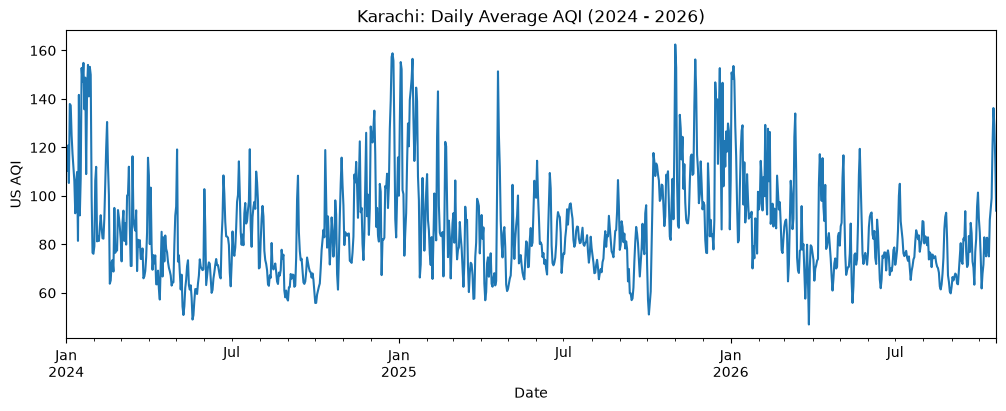

In [20]:
plt.figure(figsize = (12,4))
daily.plot()
plt.title("Karachi: Daily Average AQI (2024 - 2026)")
plt.ylabel("US AQI")
plt.xlabel("Date")
plt.show()

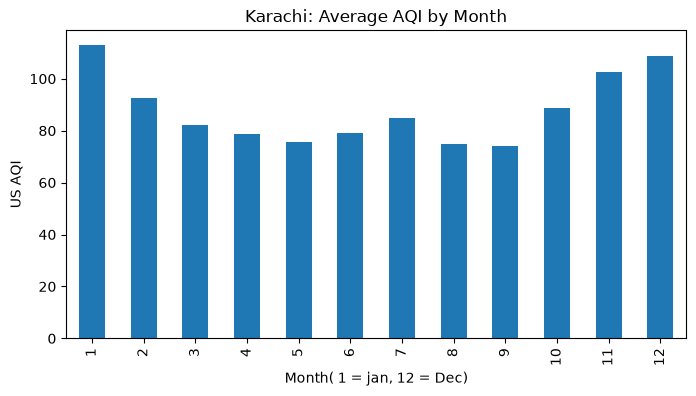

In [21]:
monthly = df.set_index("time")["us_aqi"].groupby(lambda X: X.month).mean()
plt.figure(figsize = (8,4))
monthly.plot(kind ="bar")
plt.title("Karachi: Average AQI by Month")
plt.xlabel("Month( 1 = jan, 12 = Dec)")
plt.ylabel("US AQI")
plt.show()

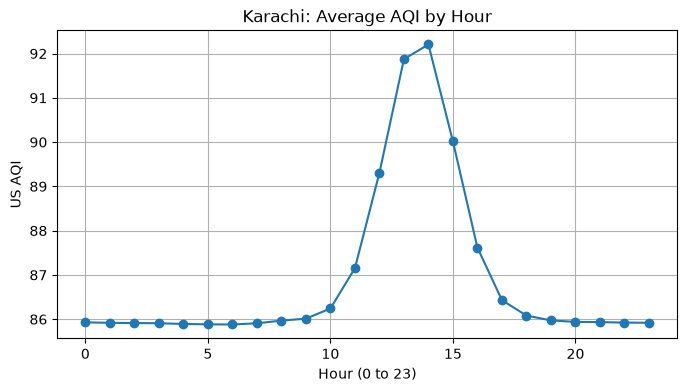

In [22]:
hourly = df.set_index("time")["us_aqi"].groupby(lambda X: X.hour).mean()
plt.figure(figsize=(8,4))
hourly.plot(marker ="o")
plt.title("Karachi: Average AQI by Hour")
plt.xlabel("Hour (0 to 23)")
plt.ylabel("US AQI")
plt.grid(True)
plt.show()

In [23]:
daily = df.set_index("time")["us_aqi"].resample("D").mean()
print ("1 Day before relation:",round(daily.autocorr(lag=1),2))
print ("2 Day before relation:",round(daily.autocorr(lag=2),2))
print ("7 Day before relation:",round(daily.autocorr(lag=7),2))

1 Day before relation: 0.8
2 Day before relation: 0.61
7 Day before relation: 0.38


In [24]:
daily_df = daily.to_frame(name="aqi")

In [25]:
daily_df ["lag_1"] = daily_df["aqi"].shift(1)
daily_df  ["lag_2"] = daily_df["aqi"].shift(2)
daily_df["lag_7"] = daily_df["aqi"].shift(7)

daily_df["roll_3"] = daily_df["aqi"].shift(1).rolling(3).mean()
daily_df["roll_7"] = daily_df["aqi"].shift(1).rolling(7).mean()

daily_df["month"] = daily_df.index.month
daily_df.head(10)

,aqi,lag_1,lag_2,lag_7,roll_3,roll_7,month
time,,,,,,,
2024-01-01,112.791667,NaN,NaN,NaN,NaN,NaN,1
2024-01-02,110.375000,112.791667,NaN,NaN,NaN,NaN,1
2024-01-03,120.791667,110.375000,112.791667,NaN,NaN,NaN,1
2024-01-04,105.333333,120.791667,110.375000,NaN,114.652778,NaN,1
2024-01-05,137.916667,105.333333,120.791667,NaN,112.166667,NaN,1
2024-01-06,137.333333,137.916667,105.333333,NaN,121.347222,NaN,1
2024-01-07,124.916667,137.333333,137.916667,NaN,126.861111,NaN,1
2024-01-08,117.333333,124.916667,137.333333,112.791667,133.388889,121.351190,1
2024-01-09,111.833333,117.333333,124.916667,110.375000,126.527778,122.000000,1


In [26]:
daily_df["target"]=daily_df["aqi"].shift(-1)
daily_df = daily_df.dropna()
print (daily_df.shape)
daily_df.head()

(1016, 8)


,aqi,lag_1,lag_2,lag_7,roll_3,roll_7,month,target
time,,,,,,,,
2024-01-08,117.333333,124.916667,137.333333,112.791667,133.388889,121.351190,1,111.833333
2024-01-09,111.833333,117.333333,124.916667,110.375000,126.527778,122.000000,1,106.166667
2024-01-10,106.166667,111.833333,117.333333,120.791667,118.027778,122.208333,1,92.833333
2024-01-11,92.833333,106.166667,111.833333,105.333333,111.777778,120.119048,1,105.875000
2024-01-12,105.875000,92.833333,106.166667,137.916667,103.611111,118.333333,1,109.875000


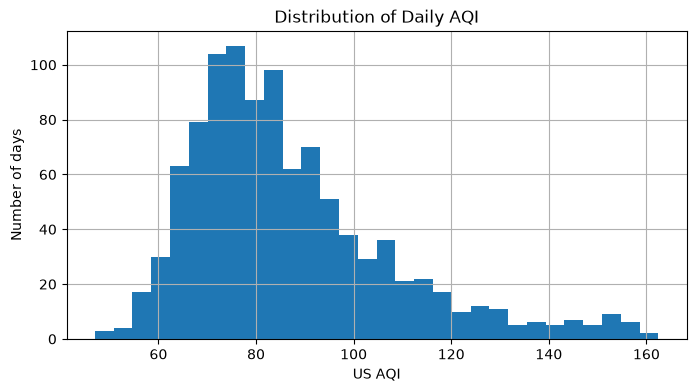

In [27]:
plt.figure(figsize=(8, 4))
daily_df["aqi"].hist(bins=30)
plt.title("Distribution of Daily AQI")
plt.xlabel("US AQI")
plt.ylabel("Number of days")
plt.show()

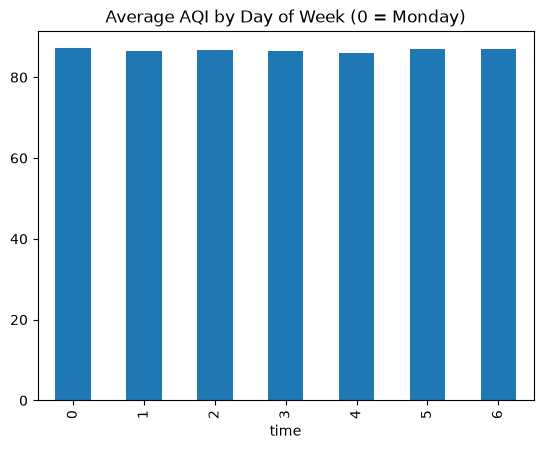

In [28]:
weekday = daily_df["aqi"].groupby(daily_df.index.dayofweek).mean()
weekday.plot(kind="bar")
plt.title("Average AQI by Day of Week (0 = Monday)")
plt.show()

In [29]:
X = daily_df.drop(columns = ['target'])
y = daily_df['target']

In [30]:
split_index  = int(len(daily_df)*0.80)

In [31]:
X_train, X_test = X.iloc[:split_index],X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index],y.iloc[split_index:]

In [32]:
print ("Traning data shape :",X_train.shape)
print ("Testing data shape :", X_test.shape)
print ("Train period: ", X_train.index.min().date(), "to", X_train.index.max().date())
print ("Testing period: ", X_test.index.min().date(), "to", X_test.index.max().date())

Traning data shape : (812, 7)
Testing data shape : (204, 7)
Train period:  2024-01-08 to 2026-03-29
Testing period:  2026-03-30 to 2026-10-19


In [33]:
y_pred_baseline = X_test['aqi']

In [34]:
baseline_mae = mean_absolute_error(y_test,y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))

In [35]:
print ("Baseline MAE:", round(baseline_mae,2))
print ("Baseline RMSE:",round(baseline_rmse, 2))

Baseline MAE: 6.31
Baseline RMSE: 8.49


In [36]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0.8 ,-0.12, 0.02,...,-0.04, 0.18, 0.11]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['aqi','lag_1','lag_2',...,'roll_3','roll_7','month']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,11.99
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [37]:
y_pred_lr = lr_model.predict(X_test)

In [38]:
lr_mae = mean_absolute_error(y_test, y_pred_lr)
lr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))

In [39]:
print ("Linear regression MAE", round(lr_mae,2))
print ("Linear regression RMSE",round(lr_rmse,2))

Linear regression MAE 6.12
Linear regression RMSE 8.2


In [40]:
rf_model = RandomForestRegressor(n_estimators= 200, max_depth = 6, min_samples_leaf = 5, random_state = 42)
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

In [41]:
y_pred_rf = rf_model.predict(X_test)

In [42]:
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_rmse = np.sqrt(mean_squared_error(y_test, y_pred_rf))

In [43]:
print ("Random Forest MAE:", round(rf_mae,2))
print ("Random Forest RMSE:", round(rf_rmse,2))

Random Forest MAE: 6.06
Random Forest RMSE: 8.37


In [44]:
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    random_state=42
)

In [45]:
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

In [46]:
xgb_mae = mean_absolute_error(y_test, y_pred_xgb)

xgb_rmse = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

In [47]:
print("XGBoost MAE:", round(xgb_mae, 2))
print("XGBoost RMSE:", round(xgb_rmse, 2))

XGBoost MAE: 5.86
XGBoost RMSE: 8.14


In [48]:
# 1. Compare Actual vs. XGBoost Predicted AQI for the last 10 days
comparison_table = pd.DataFrame({
    "Today_AQI": X_test["aqi"].round(1),
    "Actual_Next_Day_AQI": y_test.round(1),
    "Predicted_Next_Day_AQI (XGBoost)": y_pred_xgb.round(1)
})

In [49]:
print("=== Last 10 Days: Prediction vs. Actual AQI ===")
display(comparison_table.tail(10))

=== Last 10 Days: Prediction vs. Actual AQI ===


,Today_AQI,Actual_Next_Day_AQI,Predicted_Next_Day_AQI (XGBoost)
time,,,
2026-10-10,82.8,78.5,85.900002
2026-10-11,78.5,75.0,80.699997
2026-10-12,75.0,90.1,79.800003
2026-10-13,90.1,94.4,92.500000
2026-10-14,94.4,99.1,93.099998
2026-10-15,99.1,121.0,97.099998
2026-10-16,121.0,136.2,112.099998
2026-10-17,136.2,129.1,129.899994
2026-10-18,129.1,114.4,115.300003


In [51]:
# 2. Live Prediction for the very next day
latest_day_features = X_test.iloc[[-1]]  # Features from the last day in test set
tomorrow_prediction = xgb_model.predict(latest_day_features)[0]

In [52]:

print("\n--------------------------------------------------")
print(f"Last Day ({latest_day_features.index[0].date()}) AQI: {latest_day_features['aqi'].values[0]:.1f}")
print(f"--> Predicted AQI for Tomorrow (by XGBoost Winner): {tomorrow_prediction:.1f}")
print("--------------------------------------------------")


--------------------------------------------------
Last Day (2026-10-19) AQI: 114.4
--> Predicted AQI for Tomorrow (by XGBoost Winner): 105.5
--------------------------------------------------


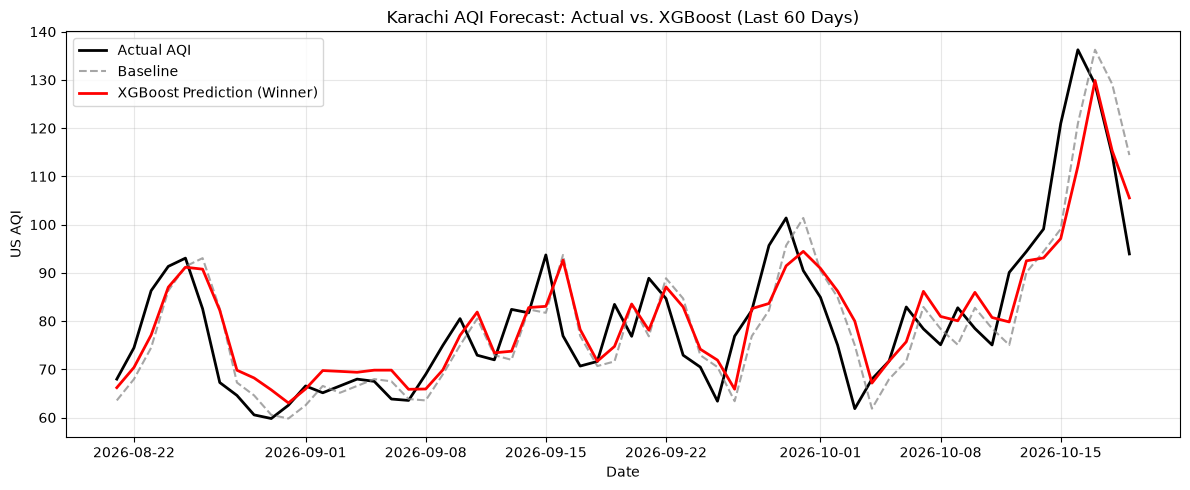

In [53]:
# Step 7: Final Comparison & Feature Importance Graphs
# 1. Graph: Actual vs. XGBoost Prediction (Last 60 Days of Test Set)
plt.figure(figsize=(12, 5))
plt.plot(y_test.index[-60:], y_test.values[-60:], label="Actual AQI", color="black", linewidth=2)
plt.plot(y_test.index[-60:], y_pred_baseline.values[-60:], label="Baseline", linestyle="--", color="gray", alpha=0.7)
plt.plot(y_test.index[-60:], y_pred_xgb[-60:], label="XGBoost Prediction (Winner)", color="red", linewidth=2)

plt.title("Karachi AQI Forecast: Actual vs. XGBoost (Last 60 Days)")
plt.xlabel("Date")
plt.ylabel("US AQI")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

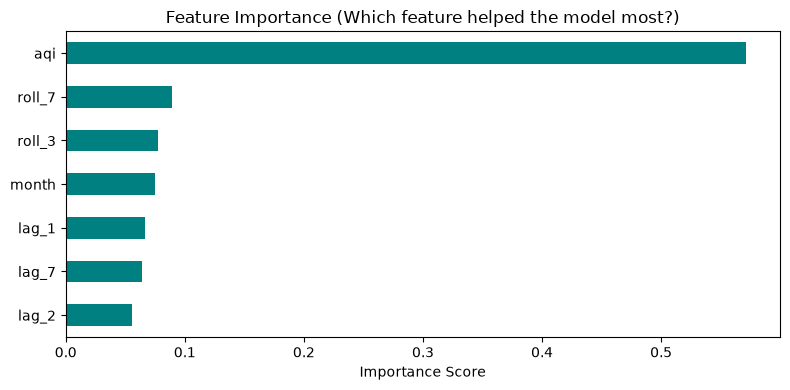

In [54]:

# 2. Graph: Feature Importance (What did XGBoost learn from?)
importances = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values()

plt.figure(figsize=(8, 4))
importances.plot(kind="barh", color="teal")
plt.title("Feature Importance (Which feature helped the model most?)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

In [55]:
import joblib
import xgboost, sklearn, pandas, numpy, matplotlib

joblib.dump(xgb_model, "xgb_model.joblib")
print("Features:", list(X_train.columns))
print("xgboost", xgboost.__version__)
print("scikit-learn", sklearn.__version__)
print("pandas", pandas.__version__)
print("numpy", numpy.__version__)
print("matplotlib", matplotlib.__version__)

Features: ['aqi', 'lag_1', 'lag_2', 'lag_7', 'roll_3', 'roll_7', 'month']
xgboost 3.4.1
scikit-learn 1.9.0
pandas 3.0.5
numpy 2.5.2
matplotlib 3.11.1


In [66]:
FEATURES = ["aqi", "lag_1", "lag_2", "lag_7", "roll_3", "roll_7", "month"]

def get_latest_features():
    url = "https://air-quality-api.open-meteo.com/v1/air-quality"
    params = {
        "latitude": 24.8607,
        "longitude": 67.0011,
        "hourly": "us_aqi",
        "past_days": 15,
        "forecast_days": 1,
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()

    hourly = pd.DataFrame(r.json()["hourly"])
    hourly["time"] = pd.to_datetime(hourly["time"])
    daily = hourly.set_index("time")["us_aqi"].resample("D").mean()

    d = daily.to_frame(name="aqi")
    d["lag_1"] = d["aqi"].shift(1)
    d["lag_2"] = d["aqi"].shift(2)
    d["lag_7"] = d["aqi"].shift(7)
    d["roll_3"] = d["aqi"].shift(1).rolling(3).mean()
    d["roll_7"] = d["aqi"].shift(1).rolling(7).mean()
    d["month"] = d.index.month

    latest = d.iloc[[-1]][FEATURES]
    return latest, daily

In [67]:
model = joblib.load("xgb_model.joblib")

latest, recent_daily = get_latest_features()
print(latest)
print("Missing values:", latest.isna().sum().sum())

pred = model.predict(latest)[0]
pred_date = latest.index[0] + pd.Timedelta(days=1)
print("Predicted AQI for", pred_date.date(), ":", round(float(pred), 1))

                   aqi  lag_1      lag_2       lag_7     roll_3     roll_7  \
time                                                                         
2026-10-26  102.666667  106.0  81.416667  114.416667  94.277778  96.083333   

            month  
time               
2026-10-26     10  
Missing values: 0
Predicted AQI for 2026-10-27 : 96.8


In [68]:
%%writefile app.py
import joblib
import pandas as pd
import requests
import streamlit as st

st.set_page_config(page_title="Karachi AirWatch", page_icon="🌫️", layout="centered")

FEATURES = ["aqi", "lag_1", "lag_2", "lag_7", "roll_3", "roll_7", "month"]

# (upar ki hadd, category, rang, text ka rang, Roman Urdu salah)
CATEGORIES = [
    (50, "Good (Acha)", "#2E9E4F", "white",
     "Hawa saaf hai. Bahar ki sargarmiyan normal rakhein."),
    (100, "Moderate (Darmiyana)", "#F2C500", "black",
     "Hawa theek hai. Bohat hassas log (dama, dil ke mareez) lambi bahar ki mehnat kam karein."),
    (150, "Unhealthy for Sensitive Groups", "#F28C1E", "black",
     "Bachay, bazurg aur dama ya dil ke mareez bahar kam jayein. Mask pehenna behtar hai."),
    (200, "Unhealthy (Kharab)", "#D63B3B", "white",
     "Sab bahar ki mehnat kam karein. Bachay aur bazurg ghar mein rahein. Mask pehnein."),
    (300, "Very Unhealthy (Bohat Kharab)", "#7B3FA0", "white",
     "Bahar jaane se parhez karein aur khidkiyan band rakhein."),
    (10_000, "Hazardous (Khatarnak)", "#7E0023", "white",
     "Bahar na niklein. Zaroorat ho to achi quality ka mask pehnein."),
]

def get_category(aqi):
    for upper, name, color, text_color, advice in CATEGORIES:
        if aqi <= upper:
            return name, color, text_color, advice

@st.cache_resource
def load_model():
    return joblib.load("xgb_model.joblib")

@st.cache_data(ttl=3600)
def get_latest():
    url = "https://air-quality-api.open-meteo.com/v1/air-quality"
    params = {
        "latitude": 24.8607,
        "longitude": 67.0011,
        "hourly": "us_aqi",
        "past_days": 15,
        "forecast_days": 1,
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()

    hourly = pd.DataFrame(r.json()["hourly"])
    hourly["time"] = pd.to_datetime(hourly["time"])
    daily = hourly.set_index("time")["us_aqi"].resample("D").mean()

    d = daily.to_frame(name="aqi")
    d["lag_1"] = d["aqi"].shift(1)
    d["lag_2"] = d["aqi"].shift(2)
    d["lag_7"] = d["aqi"].shift(7)
    d["roll_3"] = d["aqi"].shift(1).rolling(3).mean()
    d["roll_7"] = d["aqi"].shift(1).rolling(7).mean()
    d["month"] = d.index.month

    return d.iloc[[-1]][FEATURES], daily

st.title("🌫️ Karachi AirWatch")
st.caption("Kal Karachi ki hawa kaisi hogi? Aaj hi pata karo.")

try:
    model = load_model()
    latest, daily = get_latest()
except Exception as e:
    st.error("Data ya model load nahi ho saka. Internet check karein aur dobara try karein.")
    st.exception(e)
    st.stop()

pred = float(model.predict(latest)[0])
today_aqi = float(latest["aqi"].iloc[0])
pred_date = latest.index[0] + pd.Timedelta(days=1)
name, color, text_color, advice = get_category(pred)

st.markdown(
    f"""
    <div style="background:{color};color:{text_color};padding:24px;border-radius:14px;text-align:center;">
        <div style="font-size:16px;">Predicted AQI for {pred_date.strftime('%d %b %Y')}</div>
        <div style="font-size:64px;font-weight:700;line-height:1.1;">{pred:.0f}</div>
        <div style="font-size:20px;font-weight:600;">{name}</div>
    </div>
    """,
    unsafe_allow_html=True,
)

st.write("")
st.info(f"**Salah:** {advice}")

c1, c2 = st.columns(2)
c1.metric("Aaj ka AQI (average)", f"{today_aqi:.0f}")
c2.metric("Kal ki prediction", f"{pred:.0f}", f"{pred - today_aqi:+.0f}")

st.subheader("Pichle 8 din ka AQI")
st.line_chart(daily.tail(8))
with st.expander("ℹ️ Ye forecast kaise bana?"):
    st.write(
        "Ye andaza pichle dino ke AQI aur mahine ke rujhan se banaya gaya hai. "
        "Ek machine learning model ne Karachi ke 2024 se 2026 tak ke data se seekha hai "
        "ke aaj ki hawa dekh kar kal kaisi hogi.\n\n"
        "**Kuch baatein yaad rakhein:**\n"
        "- Ye poore Karachi ka aam andaza hai. Aap ke mohalle ki hawa thori mukhtalif ho sakti hai.\n"
        "- Aam tor par kal ka asal AQI is andaze se lagbhag 6 point door hota hai. "
        "Achanak dhuan, barish ya hawa badalne par farq zyada ho sakta hai, khaas tor par sardiyon mein.\n"
        "- Data Open-Meteo ki air quality service se aata hai, jo zameeni sensors ke bajaye "
        "computer models par chalti hai.\n"
        "- Agar aap ko dama, dil ya phephron ki koi bimari hai, to apne doctor ki hidayat par amal karein."
    )

st.caption("Data: Open-Meteo | Model: XGBoost | Har ghante naya data liya jata hai")

Writing app.py
